In [1]:
import numpy as np
import agama
agama.setUnits(length=1, velocity=1, mass=1)  # kpc, km/s, Solar mass
import matplotlib.pyplot as plt
from IPython.display import Latex
import sys
sys.path.append('/suphys/aani0116/Work/minicluster_model_new/my_modules/')

from scipy.stats import uniform_direction
from reverse_orbit import reverse_orbit
from mc_declare import *
pot_mw = agama.Potential('/suphys/aani0116/minicluster/minicluster_tidal/Agama/data/McMillan17.ini')
sys.path.append('/suphys/aani0116/Work/minicluster_tidal/stellar')
from N_calculator import N_encounter 
from N_calculator import stellar_rho_total
from scipy.integrate import quad
from hmf import get_mass
from times import dynamical_time
from mass_loss_new import *
from generate_particles import *
from radius_and_energy import *
from sklearn.decomposition import PCA
import corner
from mc_xv import generate_xv_at,generate_xv

kappa=3.54
beta=3.47


In [2]:
s_pos=[8.0,0.01,0.0]
R= np.linalg.norm(np.array(s_pos))



In [3]:
def stellar_energy(N,M,R,v,its_sum):
    b = np.sqrt(np.random.uniform(0, (1e-3)**2, N))
    E=((4*0.33*agama.G*agama.G*M*0.27*R*R)/((b**4)*v**2))
    E_sum=np.sum(E)
    E_rms_sum=np.sum(np.sqrt(E))**2
    if its_sum:
        return E_sum
    else:
        return E_rms_sum

In [4]:
def N_encounter_new(t,xv, b_max=1e-3): #stellar_rho_total use the better model
    return np.trapezoid(stellar_rho_total(xv[:,0], xv[:,1], xv[:,2]) * np.linalg.norm(xv[:, 3:],axis=1) * np.pi  * b_max**2,t)

In [5]:
vcirc=lambda R:np.sqrt(-R * pot_mw.force(np.column_stack((R, 0*R, 0*R)))[:, 0])
f = lambda E: np.exp(E / sigma**2)   

sigma = vcirc(R)/np.sqrt(2)                     
vesc  = np.sqrt(-2*pot_mw.potential(s_pos))                     
Psi   = pot_mw.potential(s_pos)
N     = 1000


v = np.linspace(0, vesc, 100000)
P = v**2 * f(Psi - v**2/2)
P /= P.sum()

get_speed = lambda N: np.random.choice(v, size=N, p=P)


In [6]:
def get_xv(pos):
    v=get_speed(1)[0]
    vel_unit = uniform_direction(3).rvs(1)
    vel=v * vel_unit
    return np.hstack((pos, vel[0]))


In [7]:
SD_1,SD_2,SD_3,minicluster_mass,minicluster_radius=[],[],[],[],[]

In [8]:
#going to work in solar radius 

In [9]:
for i in range(100):
    simulation_time=10
    mcp_xv,mcp_mass=np.empty((0, 6)),np.array([]) 
    mc = Minicluster(mass=get_mass(), delta=50, concentration=10)
    Nbody_total=1e5
    pmass=mc.mass/Nbody_total
    print('mass and radius:',mc.mass,mc.radius,)
    mc_center=get_xv(s_pos)
    mc_start  = mc_center.copy()
    tupd = 1e-2
    time_i = 0
    mc_mass=mc.mass
    mc_rvir=mc.radius
    #random stuff for plotting
    mc_array=[mc_center]
    mc_time=[]
    pnum_array=[]
    mass_array,radius_array=[],[]
    Ef_array,Ei_array,E2_array,E3_array,N_encounter_with_star_array =[],[],[],[],[]
    color=[0]
    SD=[]
    SD_r=[]
    SD_t=[]
    SD_axis=[]
    R_vector=[]
    color_index=0
    SD_count=0
    print(f'enter loop {i}')
    minicluster_mass.append(mc.mass)
    minicluster_radius.append(mc.radius)
    while time_i < simulation_time:   
        mc_time_center, mc_orbit_center = agama.orbit(ic=mc_center, potential=pot_mw, time=tupd,timestart=time_i,dtype=float, trajsize=1000, accuracy=1e-16,verbose=False)
        N_encounter_with_star=N_encounter_new(mc_time_center, mc_orbit_center,b_max=0.001)
        #rmin=compute_rmin(mc_time_center, mc_orbit_center)
        N_encounter_with_star_array.append(N_encounter_with_star)
        col_time=tupd/N_encounter_with_star
        its_sum=col_time<dynamical_time(mc_mass,mc_rvir)
        delE=stellar_energy(round(N_encounter_with_star),mc_mass,mc_rvir, np.mean(np.linalg.norm(mc_orbit_center[:,3:],axis=1)),its_sum)
        

        Eb=binding_energy(mc_mass,mc_rvir)
        Ei=total_energy(Eb)

        delEbyE=abs(delE/Eb)
        mass_loss=mc_mass*get_dm_frac(delEbyE)

        Ef=Ei+(1-get_fej(delEbyE))*delE-get_fub(delEbyE)*Ei
        
        Ef_array.append(Ef)
        Ei_array.append(Ei)
        E2_array.append((1-get_fej(delEbyE))*delE)
        E3_array.append(get_fub(delEbyE)*Ei)
        
        mc_mass_old=mc_mass
        mc_mass=mc_mass-mass_loss
        #mc_rvir=(kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef if N_encounter_with_star > 1 else mc_rvir     #mass and radius update
        mc_rvir=((kappa/2-beta)*agama.G*mc_mass*mc_mass/Ef) if Ef<0 else 0

        mass_array.append(mc_mass)
        radius_array.append(mc_rvir)
        mc_array.append(mc_orbit_center)
        mc_time.append(mc_time_center[-1])

        r_tidal=tidal_radius(np.linalg.norm(mc_center[:3]),mc_mass_old)
        pnum=round(mass_loss*Nbody_total/mc.mass)
        pnum_array.append(pnum)
        if mc_rvir==0:
            print('dead')
            pnum=round(mc_mass_old*Nbody_total/mc.mass)
            mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass_old,r_tidal,pnum,pmass)
            #mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0)
            #mcp_xv_temp+=mc_orbit_center[-1]
            mcp_xv_temp+=mc_center
            
            mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
            mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
            while time_i < simulation_time:
                mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=0)[:, 1])
                print('time_i',time_i)
                if mcp_xv.size>100 and SD_count%10==0:
                    mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
                    pca=PCA(n_components=3)
                    mcp_xr=pca.fit_transform(mcp_xc)
            
                    SD.append(pca.explained_variance_**0.5)
                    SD_t.append(time_i)
                    SD_r.append(pca.explained_variance_ratio_)
                    SD_axis.append(pca.components_)
                    R_vector.append(mcp_xv[:,:3].mean(axis=0))
                time_i += tupd
            
            mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
            color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
            color_index+=1 
            alive=0
            break 
        
        if mcp_xv.size>0:
            mcp_xv = np.vstack(agama.orbit(ic=mcp_xv, potential=pot_mw,time=tupd, timestart=time_i, trajsize=1, accuracy=1e-16,dtype=float,verbose=False)[:, 1])
        
        mcp_xv_temp,mcp_mass_temp=generate_mc_particles(mc_mass,r_tidal,pnum,pmass)
            #if mcp_xv.size>0: mcp_xv_temp+=np.mean(mcp_xv[:,:6],axis=0) 
        if mcp_xv.size>0:mcp_xv_temp+=mc_orbit_center[-1]
        else: mcp_xv_temp+=mc_orbit_center[-1]  
        mcp_mass=np.concatenate([mcp_mass, mcp_mass_temp], axis=0)
        mcp_xv=np.concatenate([mcp_xv, mcp_xv_temp], axis=0)
    
        if pnum>0:
            color=np.concatenate([color,np.ones_like(mcp_mass_temp)*color_index])
            color_index+=1 

        mc_center = mc_orbit_center[-1]

        time_i += tupd
        if mcp_xv.size>100 and SD_count%10==0:
            mcp_xc=mcp_xv[:,:3]-mcp_xv[:,:3].mean(axis=0)
            pca=PCA(n_components=3)
            mcp_xr=pca.fit_transform(mcp_xc)

            SD.append(pca.explained_variance_**0.5)
            SD_t.append(time_i)
            SD_r.append(pca.explained_variance_ratio_)
            SD_axis.append(pca.components_)
            R_vector.append(mcp_xv[:,:3].mean(axis=0))
        SD_count+=1
        
    color=np.array(color[1:])
   


    if mcp_xv.size>100:
        SD=np.array(SD)
        SD_1.append(SD[-5:-1,0].mean())
        SD_2.append(SD[-5:-1,1].mean())
        SD_3.append(SD[-5:-1,2].mean())
    else:
        SD_1.append(0)
        SD_2.append(0)
        SD_3.append(0)
    

    print(i,'done','SD',SD_1[-1],SD_2[-1],SD_3[-1])
i+=1



mass and radius: 1.1194613958132793e-14 1.7990197961568823e-12
enter loop 0


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


0 done SD 0 0 0
mass and radius: 4.963972118264428e-13 6.367603501439294e-12
enter loop 1
1 done SD 0 0 0
mass and radius: 1.6488522431241222e-14 2.046885179629798e-12
enter loop 2
2 done SD 0 0 0
mass and radius: 2.413492110180583e-13 5.007045403083891e-12
enter loop 3
3 done SD 0 0 0
mass and radius: 2.2239618653333145e-13 4.872389669607476e-12
enter loop 4
4 done SD 0 0 0
mass and radius: 2.843486002951511e-14 2.4546143376480523e-12
enter loop 5
5 done SD 0 0 0
mass and radius: 1.3380445682195939e-14 1.9092219915002028e-12
enter loop 6
6 done SD 0 0 0
mass and radius: 1.224784555262291e-13 3.993798370531194e-12
enter loop 7
7 done SD 0 0 0
mass and radius: 3.2257089038939405e-14 2.560007824560551e-12
enter loop 8
8 done SD 0 0 0
mass and radius: 2.0294595589825692e-14 2.193611439393162e-12
enter loop 9
9 done SD 0 0 0
mass and radius: 2.936770502693169e-14 2.4811683817605446e-12
enter loop 10
10 done SD 1.2324911667056582e-05 1.1737678408136305e-06 3.678325193948154e-07
mass and rad

/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


15 done SD 0 0 0
mass and radius: 3.5234415839979438e-12 1.2237384155110441e-11
enter loop 16
16 done SD 0 0 0
mass and radius: 1.656524793522774e-13 4.416709972850436e-12
enter loop 17
17 done SD 0 0 0
mass and radius: 6.817206745403279e-15 1.5248778525339125e-12
enter loop 18
18 done SD 0 0 0
mass and radius: 1.086151613110586e-14 1.7809964435693644e-12
enter loop 19
19 done SD 0 0 0
mass and radius: 5.349852202790746e-13 6.52850132287089e-12
enter loop 20
20 done SD 0 0 0
mass and radius: 8.688744134981845e-15 1.6533009089374047e-12
enter loop 21


...

83 done SD 0 0 0
mass and radius: 9.074117996156936e-14 3.6138299195560446e-12
enter loop 84
84 done SD 3.9487554671742486e-05 3.4503823727645277e-06 1.025199689776213e-06
mass and radius: 1.8999462100167848e-14 2.1459190588723753e-12
enter loop 85


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


85 done SD 0 0 0
mass and radius: 1.573266268011171e-14 2.0151172100315683e-12
enter loop 86
86 done SD 0 0 0
mass and radius: 4.3832290380678523e-14 2.8355085200046085e-12
enter loop 87
87 done SD 0 0 0
mass and radius: 8.638587427182875e-15 1.6501134821619247e-12
enter loop 88
88 done SD 6.029462750882729e-07 8.631702442321698e-08 6.292681449803827e-08
mass and radius: 5.832962747746383e-14 3.1188606379001457e-12
enter loop 89
89 done SD 0 0 0
mass and radius: 5.017340891365405e-14 2.9661340295619995e-12
enter loop 90
90 done SD 0 0 0
mass and radius: 4.214105688283852e-14 2.7985605610444437e-12
enter loop 91


/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:8: RuntimeWarning: divide by zero encountered in log10
  get_dm_frac=lambda dE_dummy:10**dm_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:11: RuntimeWarning: divide by zero encountered in log10
  get_fej=lambda dE_dummy:fej_interp(np.log10(dE_dummy))
/suphys/aani0116/Work/minicluster_model_new/my_modules/mass_loss_new.py:17: RuntimeWarning: divide by zero encountered in log10
  get_fub=lambda dE_dummy:fub_interp(np.log10(dE_dummy))


91 done SD 0 0 0
mass and radius: 2.5316209551901554e-14 2.361379538144963e-12
enter loop 92
92 done SD 0 0 0
mass and radius: 1.2355618390559743e-14 1.8591783947516933e-12
enter loop 93
93 done SD 0 0 0
mass and radius: 7.284672603023346e-13 7.236072580822505e-12
enter loop 94
94 done SD 0 0 0
mass and radius: 3.788062506957791e-14 2.7008799483315222e-12
enter loop 95
95 done SD 0 0 0
mass and radius: 5.030662727760635e-14 2.9687568950948757e-12
enter loop 96
96 done SD 0 0 0
mass and radius: 1.0606140314384572e-14 1.7669273418370363e-12
enter loop 97
97 done SD 0 0 0
mass and radius: 2.0489140098411875e-13 4.741045745077354e-12
enter loop 98
98 done SD 1.6774623585056173e-06 1.7023719232669232e-07 8.172407262001646e-08
mass and radius: 1.0757530473996656e-13 3.8247562536740966e-12
enter loop 99
99 done SD 0 0 0


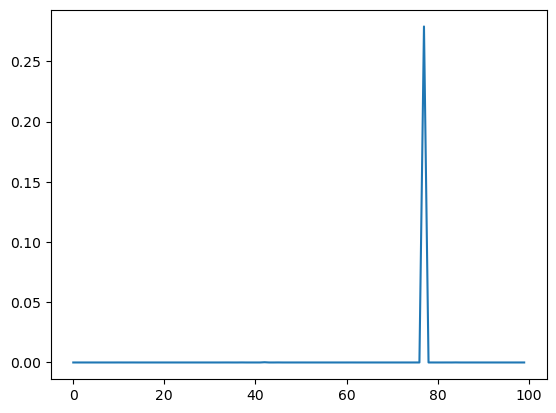

In [12]:
plt.plot(SD_1,label='SD_1')


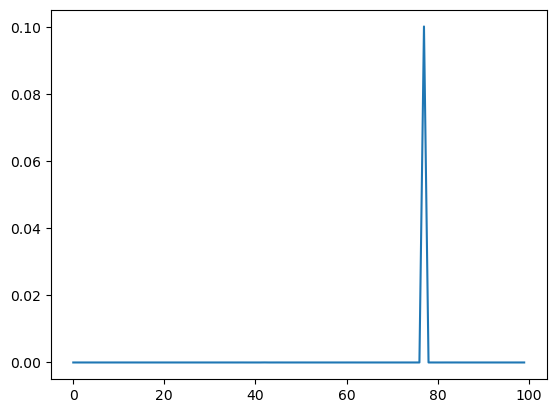

In [13]:
plt.plot(SD_2,label='SD_2')


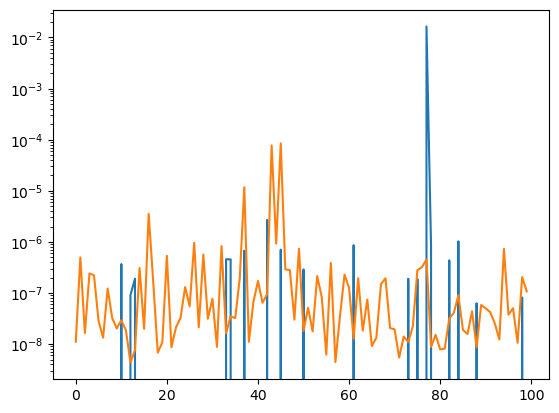

In [14]:
plt.plot(SD_3,label='SD_3')
plt.plot(np.array(minicluster_mass)/1e-6,label='minicluster_radius')

plt.yscale('log')

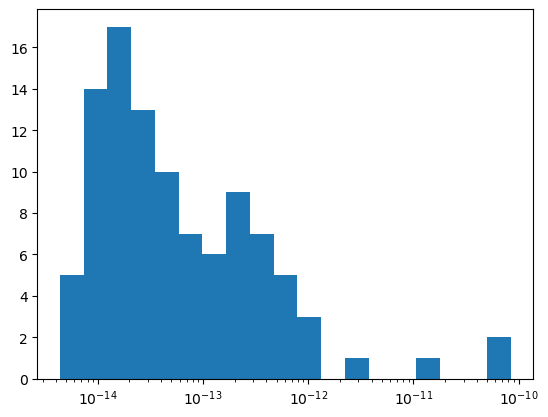

In [15]:
bin=np.logspace(np.log10(min(minicluster_mass)),np.log10(max(minicluster_mass)),20)
plt.hist(minicluster_mass,bins=bin)
plt.xscale('log')

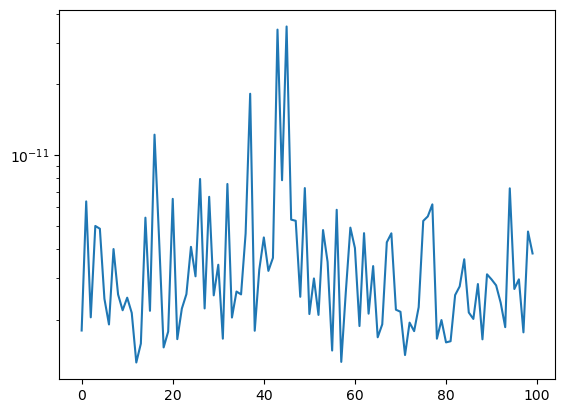

In [16]:
plt.plot(minicluster_radius,label='minicluster_radius')
plt.yscale('log')